<a href="https://colab.research.google.com/github/PoojithaUndavalli/LSTM-Network/blob/main/DL_Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

In [ ]:
import urllib.request

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

urllib.request.urlretrieve(url, "shakespeare.txt")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [ ]:
with open("shakespeare.txt", "r", encoding="utf-8") as file:
    text = file.read()

print("Total characters:", len(text))
print("\nFirst 1000 characters:\n")
print(text[:1000])

Total characters: 1115394

First 1000 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak thi

In [ ]:
text = text[:500000]

print("Characters used:", len(text))

Characters used: 500000


In [ ]:
text = text.lower()

print(text[:500])

first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us kill him, and we'll have corn at our own price.
is't a verdict?

all:
no more talking on't; let it be done: away, away!

second citizen:
one word, good citizens.

first citizen:
we are accounted poor


In [ ]:
tokenizer = Tokenizer()

tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Total vocabulary size:", total_words)

Total vocabulary size: 8244


In [ ]:
input_sequences = []

for line in text.split("\n"):

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequence = token_list[:i + 1]
        input_sequences.append(sequence)

print("Total sequences:", len(input_sequences))

Total sequences: 76514


In [ ]:
max_sequence_len = max(len(sequence) for sequence in input_sequences)

print("Maximum sequence length:", max_sequence_len)

Maximum sequence length: 16


In [ ]:
input_sequences = np.array(
    pad_sequences(
        input_sequences,
        maxlen=max_sequence_len,
        padding="pre"
    )
)

print("Shape of sequences:", input_sequences.shape)

Shape of sequences: (76514, 16)


In [ ]:
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (76514, 15)
y shape: (76514,)


In [ ]:
max_samples = 100000

X = X[:max_samples]
y = y[:max_samples]

print("Training samples:", len(X))

Training samples: 76514


In [ ]:
y = tf.keras.utils.to_categorical(
    y,
    num_classes=total_words
)

print("y shape:", y.shape)

y shape: (76514, 8244)


In [ ]:
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=100
    ),

    LSTM(128),

    Dense(
        total_words,
        activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    X,
    y,
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 70s 113ms/step - accuracy: 0.0341 - loss: 6.9450
Epoch 2/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 79s 109ms/step - accuracy: 0.0486 - loss: 6.5400
Epoch 3/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 85s 114ms/step - accuracy: 0.0673 - loss: 6.2889
Epoch 4/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 79s 110ms/step - accuracy: 0.0869 - loss: 6.0499
Epoch 5/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 65s 108ms/step - accuracy: 0.0973 - loss: 5.8652
Epoch 6/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 83s 110ms/step - accuracy: 0.1034 - loss: 5.7092
Epoch 7/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 65s 108ms/step - accuracy: 0.1103 - loss: 5.5666
Epoch 8/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 85s 113ms/step - accuracy: 0.1166 - loss: 5.4311
Epoch 9/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 65s 109ms/step - accuracy: 0.1216 - loss: 5.3031
Epoch 10/10
598/598 ━━━━━━━━━━━━━━━━━━━━ 82s 109ms/step - accuracy: 0.1269 - loss: 5.1791


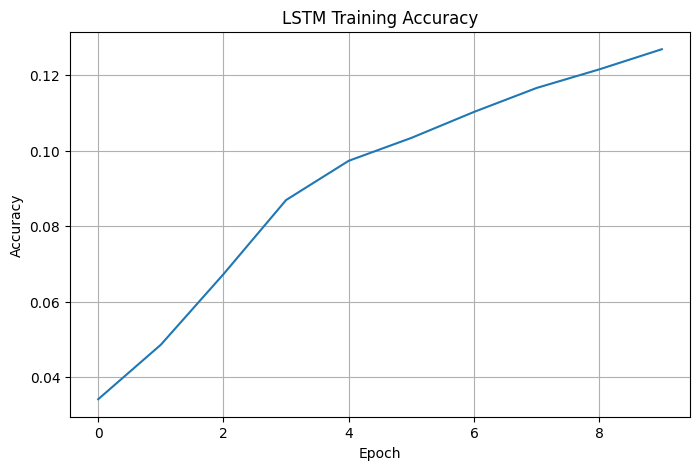

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"])

plt.title("LSTM Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.show()

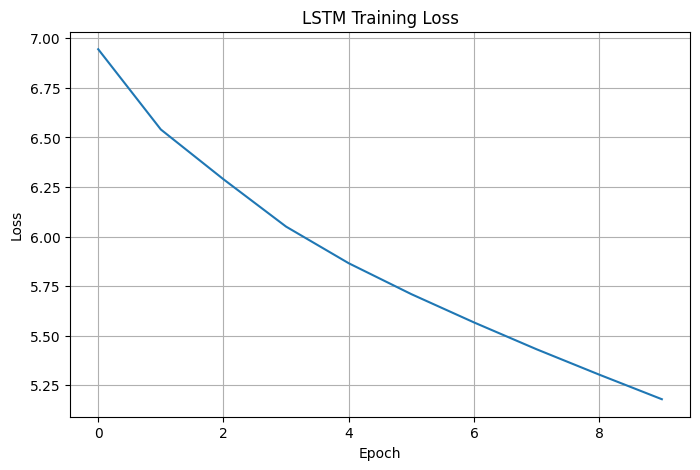

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"])

plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [ ]:
def predict_next_word(seed_text):

    token_list = tokenizer.texts_to_sequences([seed_text])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding="pre"
    )

    predicted = model.predict(
        token_list,
        verbose=0
    )

    predicted_word_index = np.argmax(predicted, axis=-1)[0]

    for word, index in tokenizer.word_index.items():

        if index == predicted_word_index:
            return word

    return ""

In [ ]:
seed_text = "to be"

predicted_word = predict_next_word(seed_text)

print("Input:", seed_text)
print("Predicted next word:", predicted_word)

Input: to be
Predicted next word: a


In [ ]:
def generate_text(seed_text, num_words):

    result = seed_text

    for _ in range(num_words):

        next_word = predict_next_word(result)

        result += " " + next_word

    return result

In [ ]:
seed_text = "to be"

generated_text = generate_text(seed_text, 10)

print("Generated text:")
print(generated_text)

Generated text:
to be a man of the king of the king is not


In [ ]:
test_sentences = [
    "to be",
    "my lord",
    "i am",
    "the king",
    "what is"
]

for sentence in test_sentences:

    prediction = predict_next_word(sentence)

    print(f"{sentence} → {prediction}")

to be → a
my lord → of
i am → a
the king → of
what is → the
